In [1]:
import torch
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
from transformers import WhisperProcessor, WhisperForConditionalGeneration

import re
from jiwer import wer

/opt/anaconda3/envs/keras/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1109 12:23:19.558000 36520 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


# 1. Liiketoiminnan ymmärtäminen

# 2. Datan ymmärtäminen

Datana on yhteensä 23 suomenkielistä ääninäytettä, joista 8 on ladattu [Mozilla Common Voice -aineistosta](https://mozilladatacollective.com/datasets/cmu5vgfuk00aunq07xzlhzvxg) ja 15 on itse äänitettyjä. Kuulon perusteella on arvioitu, onko puhuja mies, nainen vai lapsi, sekä litteroitu, mitä äänitteessä oikeasti sanotaan. Litterointeja käytetään myöhemmin Whisper-mallien tunnistustulosten vertailuun.

Omia ääninäytteitä otin sekä selkeissä olosuhteissa että taustakohinan kanssa, kuten vesihanan ja pyykkikoneen äänen kuuluessa. Lisäksi yhdessä äänitteessä käytetään murteellista puhetta. Yhteensä 16 äänitettä on selkeitä, 2 murteella tai slangilla, 4 on taustahälyä ja yksi englanniksi. Kaikki `oma_*`-äänitteet ovat Elias Rinteen puhumia.

Alla olevassa taulukossa on esitetty käytetyt äänitteet, niiden kuvaukset ja litteroinnit.

| Tiedoston nimi | Kuvailu | Mitä äänitteessä sanotaan (litterointi) |
|---|---|---|
| common_voice_fi_22986631.mp3 | Ladattu ääni, mies, selkeä | Mitä nyt tekisimme? |
| common_voice_fi_25286493.mp3 | Ladattu ääni, mies, selkeä | Niillä ansioilla ostettuja kelloja |
| common_voice_fi_25299325.mp3 | Ladattu ääni, nainen, selkeä | Nousin ylös olennon vierestä ja kävelin ohjaamoa kohti. |
| common_voice_fi_25299573.mp3 | Ladattu ääni, nainen, selkeä | Äänestin myös ensimmäistä rautatiepakettia vastaan. |
| common_voice_fi_30419449.mp3 | Ladattu ääni, nainen, selkeä | Äänestimme puolesta korjataksemme tehdyn virheen. |
| common_voice_fi_32682465.mp3 | Ladattu ääni, nainen, selkeä | Samaan aikaan mahdollistetaan työmatkaliikenne sisärajoilla vastaavalla tavalla kuin toimitaan länsi- ja pohjoisrajoilla. |
| common_voice_fi_49679457.mp3 | Ladattu ääni, lapsi (tyttö), selkeä | Äänestin mietintöä vastaan. |
| common_voice_fi_49679459.mp3 | Ladattu ääni, lapsi (tyttö), selkeä | Ville oli ihmeissään. |
| oma_1.m4a | Oma äänite, mies, selkeä | Kiva on kivaa kakka on kakkaa. |
| oma_10_korkea.m4a | Oma äänite, mies, selkeä, korkea | Ville oli ihmeissään. |
| oma_11_matala.m4a | Oma äänite, mies, selkeä, matala | Ville oli ihmeissään. |
| oma_12_pyykki.m4a | Oma äänite, mies, hälinä (pyykinlinkous) | Pyykinpesu on kovempi. Paljon taustahälynää. |
| oma_13.m4a | Oma äänite, nainen, selkeä | Hieno sininen paita tuossa. |
| oma_14_stadin_slangi.m4a | Oma äänite, nainen, stadin slangi | Mageet kledjut tos. |
| oma_2.m4a | Oma äänite, mies, selkeä | Paljon tekstiä paljon sähinää. Jee. |
| oma_3.m4a | Oma äänite, mies, selkeä | Joskus vois tehä toisinaan taas ei. |
| oma_4.m4a | Oma äänite, mies, selkeä | Mulla on tylsää. Äänittäminen on tylsää. |
| oma_5.m4a | Oma äänite, mies, selkeä | Joskus vois tehä asiat toisin. Mutta ei tällä kertaa. |
| oma_6_vesi.m4a | Oma äänite, mies, taustahäly: vesihana | Otetaan vähän taustakohinaa mukaan. Kivasti lavuaari vuotaa. |
| oma_7_vesi.m4a | Oma äänite, mies, taustahäly: vesihana | Otetaan toinen samanlainen. Vähän lisää tätä vettä. Jee. |
| oma_8_pyykki.m4a | Oma äänite, mies, taustahäly: pyykkikone | Vähän lisää pyykinpesu mukana tässä. Jee. |
| oma_9_murre.m4a | Oma äänite, mies, murteellinen puhe, selkeä | Tokkopa ny mikkää mennee piellöö. |
| oma_english.m4a | Oma äänite, mies, englanniksi | It's not a bug. It's a feature. |


# 3. Datan valmistelu

## 3.1 Esivalmistellaan data librosalla
Ensin muutetaan ääninäytteet lukujonoiksi käyttäen librosaa. Tällöin saadaan äänitteet käsiteltävään muotoon WHisperProcessorille.

In [2]:
# dictionaryyn kaikki sampleiden oikeat tekstit vertailua varten
transcriptions = {
    "common_voice_fi_22986631.mp3": "Mitä nyt tekisimme?",
    "common_voice_fi_25286493.mp3": "Niillä ansioilla ostettuja kelloja",
    "common_voice_fi_25299325.mp3": "Nousin ylös olennon vierestä ja kävelin ohjaamoa kohti.",
    "common_voice_fi_25299573.mp3": "Äänestin myös ensimmäistä rautatiepakettia vastaan.",
    "common_voice_fi_30419449.mp3": "Äänestimme puolesta korjataksemme tehdyn virheen.",
    "common_voice_fi_32682465.mp3": "Samaan aikaan mahdollistetaan työmatkaliikenne sisärajoilla vastaavalla tavalla kuin toimitaan länsi- ja pohjoisrajoilla.",
    "common_voice_fi_49679457.mp3": "Äänestin mietintöä vastaan.",
    "common_voice_fi_49679459.mp3": "Ville oli ihmeissään.",
    "oma_1.m4a": "Kiva on kivaa kakka on kakkaa.",
    "oma_10_korkea.m4a": "Ville oli ihmeissään.",
    "oma_11_matala.m4a": "Ville oli ihmeissään.",
    "oma_12_pyykki.m4a": "Pyykinpesu on kovempi. Paljon taustahälynää.",
    "oma_13.m4a": "Hieno sininen paita tuossa.",
    "oma_14_stadin_slangi.m4a": "Mageet kledjut tos.",
    "oma_2.m4a": "Paljon tekstiä paljon sähinää. Jee.",
    "oma_3.m4a": "Joskus vois tehä toisinaan taas ei.",
    "oma_4.m4a": "Mulla on tylsää. Äänittäminen on tylsää.",
    "oma_5.m4a": "Joskus vois tehä asiat toisin. Mutta ei tällä kertaa.",
    "oma_6_vesi.m4a": "Otetaan vähän taustakohinaa mukaan. Kivasti lavuaari vuotaa.",
    "oma_7_vesi.m4a": "Otetaan toinen samanlainen. Vähän lisää tätä vettä. Jee.",
    "oma_8_pyykki.m4a": "Vähän lisää pyykinpesu mukana tässä. Jee.",
    "oma_9_murre.m4a": "Tokkopa ny mikkää mennee piellöö.",
    "oma_english.m4a": "It's not a bug. It's a feature."
}

In [3]:
from pathlib import Path
from IPython.display import Audio, HTML, display
import html

# .mp3 on ladatut ja .m4a on macbookilla äänitetyt
suffixes = [".mp3", ".m4a"]

audio_dir = Path("aanitteet")
dataset = []

for file in sorted(audio_dir.iterdir()):
    if file.suffix.lower() not in suffixes:    # tarkistaa että pääte kuuluu päätejoukkoon jatkaakseen
        continue

    audio, sr = librosa.load(file, sr=16000)   # Lukee äänen lukujonoksi ja muuntaa näytteenottotaajuuden 16 000 Hz:iin

    dataset.append({
        "filename": file.name,
        "audio": audio,
        "sample_rate": sr
    })

print(f"Ladattu {len(dataset)} äänitettä\n")

cards = []

for sample in dataset:
    player = Audio(
        data=sample["audio"],
        rate=sample["sample_rate"]
    )._repr_html_()

    cards.append(f"""
        <div style="padding: 12px; border: 1px solid #ccc; border-radius: 8px;">
            <div style="display: flex; justify-content: space-between; align-items: center;">
                <b>{html.escape(sample["filename"])}</b>
                <span>{len(sample["audio"]) / sample["sample_rate"]:.2f} s</span>
            </div>
            <div style="margin-top: 10px;">
                {player}
            </div>
        </div>
    """)

display(HTML(f"""
    <div>
        <h1>Ääninäytteet:</h1>
        <div style="
            display: grid;
            grid-template-columns: repeat(3, minmax(0, 1fr));
            gap: 12px;
        ">
            {''.join(cards)}
        </div>
    </div>
"""))

/var/folders/wh/9dhw52gj7c18zhl8y4z0dy9w0000gn/T/ipykernel_36520/2118233211.py:15: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(file, sr=16000)   # Lukee äänen lukujonoksi ja muuntaa näytteenottotaajuuden 16 000 Hz:iin
/opt/anaconda3/envs/keras/lib/python3.11/site-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Ladattu 23 äänitettä



## 3.2 Mel spektogrammi ekalle näytteelle

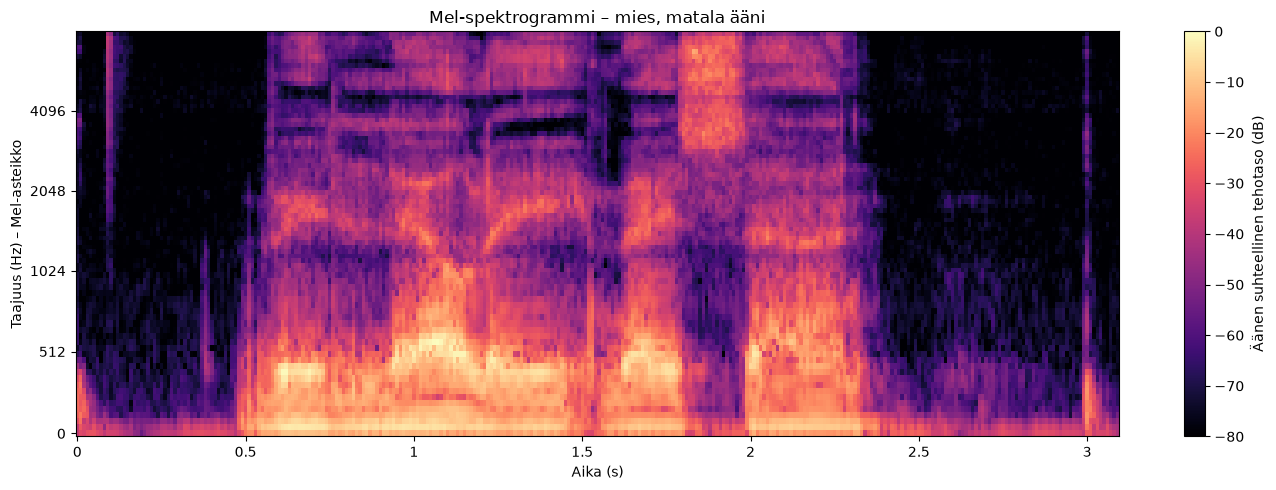

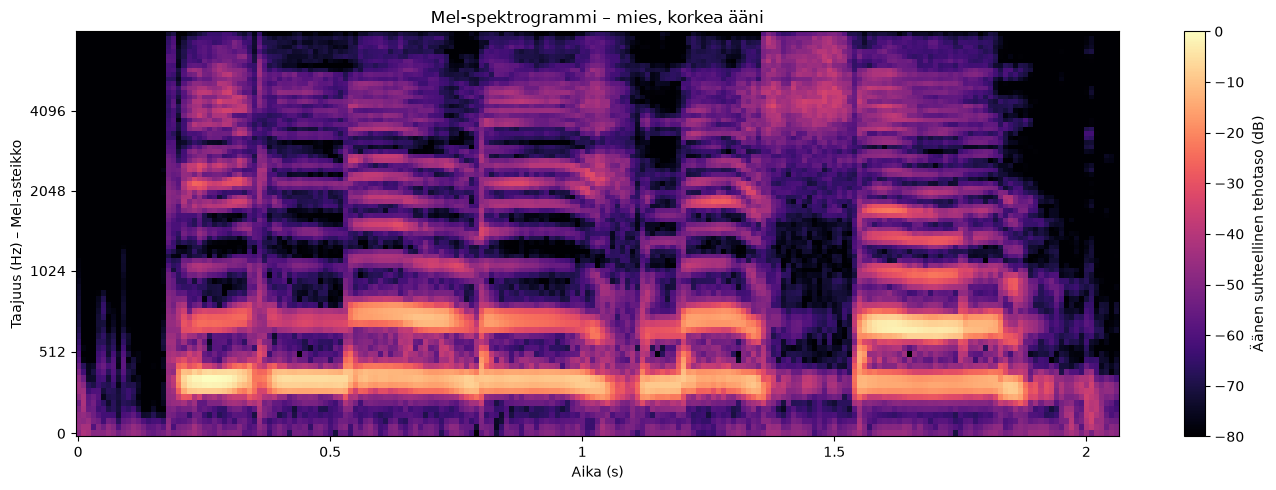

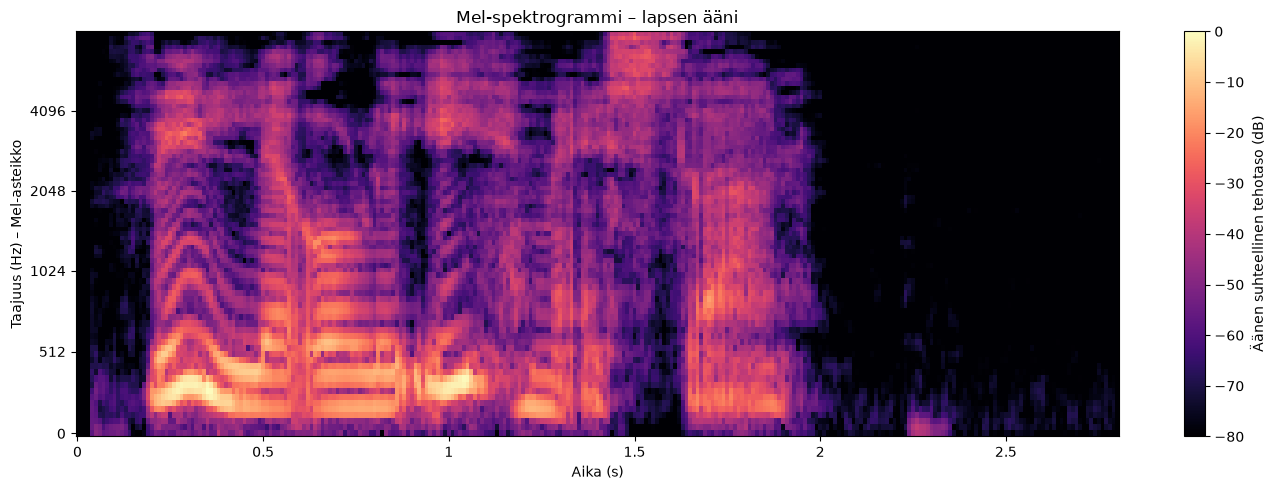

In [4]:
import librosa
# Valitut ääninäytteet mies matala, mies korkea ja lapsi

# Matalampi miehen ääni
sample_deep = next(sample for sample in dataset if sample["filename"] == "oma_11_matala.m4a")
audio_deep = np.asarray(sample_deep["audio"])
sr_deep = sample_deep["sample_rate"]

# Korkea miehen ääni
sample_high = next(sample for sample in dataset if sample["filename"] == "oma_10_korkea.m4a")
audio_high = np.asarray(sample_high["audio"])
sr_high = sample_high["sample_rate"]

# Lapsen ääni
sample_child = next(sample for sample in dataset if sample["filename"] == "common_voice_fi_49679459.mp3")
audio_child = np.asarray(sample_child["audio"])
sr_child = sample_child["sample_rate"]


# Mel-spektrogrammi miehelle matala
mel_deep = librosa.feature.melspectrogram(
    y=audio_deep,
    sr=sr_deep,
    n_fft=400,
    hop_length=160,
    win_length=400,
    n_mels=80,
    fmax=8000
)

# Mel-spektrogrammi miehelle korkea
mel_high = librosa.feature.melspectrogram(
    y=audio_high,
    sr=sr_high,
    n_fft=400,
    hop_length=160,
    win_length=400,
    n_mels=80,
    fmax=8000
)

# Mel-spektrogrammi lapselle
mel_child = librosa.feature.melspectrogram(
    y=audio_child,
    sr=sr_child,
    n_fft=400,
    hop_length=160,
    win_length=400,
    n_mels=80,
    fmax=8000
)

# Muunnetaan teho desibeleiksi
mel_db_deep = librosa.power_to_db(mel_deep, ref=np.max)
mel_db_high = librosa.power_to_db(mel_high, ref=np.max)
mel_db_child = librosa.power_to_db(mel_child, ref=np.max)


# Kuvaaja matala
plt.figure(figsize=(14, 5))

librosa.display.specshow(
    mel_db_deep,
    sr=sr_deep,
    hop_length=160,
    x_axis="time",
    y_axis="mel",
    cmap="magma",
    vmin=-80,
    vmax=0
)

plt.colorbar(label="Äänen suhteellinen tehotaso (dB)")
plt.title("Mel-spektrogrammi – mies, matala ääni")
plt.xlabel("Aika (s)")
plt.ylabel("Taajuus (Hz) – Mel-asteikko")

plt.tight_layout()
plt.show()

print("")

# Kuvaaja korkea
plt.figure(figsize=(14, 5))

librosa.display.specshow(
    mel_db_high,
    sr=sr_high,
    hop_length=160,
    x_axis="time",
    y_axis="mel",
    cmap="magma",
    vmin=-80,
    vmax=0
)

plt.colorbar(label="Äänen suhteellinen tehotaso (dB)")
plt.title("Mel-spektrogrammi – mies, korkea ääni")
plt.xlabel("Aika (s)")
plt.ylabel("Taajuus (Hz) – Mel-asteikko")

plt.tight_layout()
plt.show()

print("")

# Kuvaaja lapsi
plt.figure(figsize=(14, 5))

librosa.display.specshow(
    mel_db_child,
    sr=sr_child,
    hop_length=160,
    x_axis="time",
    y_axis="mel",
    cmap="magma",
    vmin=-80,
    vmax=0
)

plt.colorbar(label="Äänen suhteellinen tehotaso (dB)")
plt.title("Mel-spektrogrammi – lapsen ääni")
plt.xlabel("Aika (s)")
plt.ylabel("Taajuus (Hz) – Mel-asteikko")

plt.tight_layout()
plt.show()

### 3.2.1 Spektrogrammin tulkinta

X-akseli kuvaa ääninäytteen etenemistä sekunneissa. Y-akseli kuvaa äänen taajuuksia Mel-asteikolla. Matalammat hertsilukemat vastaavat matalampia taajuuksia ja suuremmat hertsilukemat korkeampia taajuuksia. Väri kertoo äänen suhteellisen tehon desibeleinä tietyllä taajuusalueella. Mitä vaaleampi väri on, sitä enemmän äänen energiaa kyseisellä alueella esiintyy. Spektrogrammit kuvaa sitä, miten äänen taajuusrakenne muuttuu eri puhetavoilla. Ensimmäiset, omat näytteet, ovat monotonisia ja viimeinen lapsen näyte sisältää vaihtelua. Kuvaaja siis on äänen taajuussisällön ajan funktiona.

Matalan ja korkean äänen spektrogrammeissa näkyy selkeitä eroja, vaikka molemmissa sanotaan sama lause. Matalan äänen näytteessä energiaa esiintyy laajasti eri taajuuksilla, myös yli 4000 hertsin alueella. Tämä ei kuitenkaan tarkoita, että äänen perustaajuus olisi näin korkea.

Korkean äänen spektrogrammissa näkyy selkeämmin vaakasuuntaisia taajuusjuovia. Niiden välinen etäisyys liittyy äänen perustaajuuteen. Korkeammalla äänellä puhuttaessa perustaajuus on yleensä suurempi kuin matalalla äänellä puhuttaessa.

### 3.2.2 Miksi muutos Transformer malleille?

Käsittelemätön raaka äänite sisältää suuren määrän näytteitä, joista mallin on vaikea oppia piirteitä. Log-Mel spektogrammi kuvaa äännäytteen äänen taajuussisällön ajan funktiona, josta kone oppii piirteet paremmin. Mel-asteikko huomioi ihmisen kuulon epälineaarisen taajuushavainnon ja logaritminen skaalaus pienentää voimakkaiden ja hiljaisten äänien välistä eroa. Tämä helpottaa äänenvoimakkuuden ja äänenpainon muutoksien vaikutusta oppimiseen.

Datan ajallinen askelmäärä tippuu huomattavasti 30 sekunnin ääninäytteestä n. 480 000:sta n. 3000 (ainakin Tiny mallilla). Askelmääriä, eli näytemääriä, voidaan tiputtaa vielä yskiulotteisella konvoluutiokerroksella puoleen n. 1500.

Librosalla muodostettiin Mel-spektrogrammit, joiden tehoarvot muunnettiin desibeleiksi visualisointia varten. WhisperProcessor käyttää samankaltaista menetelmää, mutta tekee lisäksi mallin vaatiman skaalauksen ja normalisoinnin.

### 3.2.3 Whisper ero vastaaviin teksti Transformer malleihin

Osan 1 tekstigeneraattori käsittelee tekstiä tokeneina, jotka muunnetaan vektoreiksi. Whisper puolestaan muuntaa äänisignaalin mel-spektrogrammiksi, jonka piirteet muunnetaan transformer-enkooderin käsiteltäväksi. Molemmissa käytetään attention-mekanismia syötteen eri osien välisten riippuvuuksien oppimiseen. Whisper hyödyntää enkooderi–dekooderi-arkkitehtuuria, jossa enkooderi käsittelee äänipiirteet ja dekooderi tuottaa tekstin tokeneita yksi kerrallaan.

## 3.3 Prosessoidaan data Whisperille

Prosessoidaan data Whisperille käyttäen WhisperPreprocess. WhisperProcess muokkaa raa'an ääninäytteen helpommin opittavaksi Log Mel spektogrammiksi. WhisperProcessor myös tokenisoi tekstin. Kokeilen malleja tiny, small, base, medium, large V3 ja turbo.
### 3.2.1 Ladataan prosessointi mallit tokenilla (nopeempi) tai ilman.

In [5]:
from transformers import WhisperProcessor
import os

models = {}

# Tarkistetaan token
hf_token = os.environ.get("HF_TOKEN")

if hf_token:
    print("Token löytyi.")
else:
    print("Tokenia ei löytynyt. Tarkista onko token syötetty oikeaan ympäristöön (esim keras ympäristöön)")

# Käytetään tokenia jos löytyy, jos ei menee tokenitta
models["tiny"] = WhisperProcessor.from_pretrained("openai/whisper-tiny", token=hf_token)
models["small"] = WhisperProcessor.from_pretrained("openai/whisper-small", token=hf_token)
models["base"] = WhisperProcessor.from_pretrained("openai/whisper-base", token=hf_token)
models["medium"] = WhisperProcessor.from_pretrained("openai/whisper-medium", token=hf_token)
# tän hetkinen tarkin malli V3, minkä löysin, mutta raskas
models["large"] = WhisperProcessor.from_pretrained("openai/whisper-large-v3", token=hf_token) 
# optimoitu large v3 malli, mutta hieman heikompi tarkkuus
models["turbo"] = WhisperProcessor.from_pretrained("openai/whisper-large-v3-turbo", token=hf_token)

Token löytyi.


### 3.3 Näytteiden prosessointi

Prosessoidaan näytteet Whisper mallille helpommin tulkittavaan muotoon, eli 16 000 Hz näytetiheys ja 80 Mel-taajuuskaistaa (tiny-medium) ja 128 Mel-taajuuskaistaa (large v3 ja large v3 turbo). Näytteet menee muotoon (1, 80, 3000) tiny-medium ja (1, 128, 3000) large V3 ja large V3 turbo.

#### 3.3.1 Tiny

In [6]:
samples = {}

In [7]:
samples_tiny = []

for sample in dataset:
    features = models["tiny"](
        sample["audio"],
        sampling_rate=sample["sample_rate"],
        return_tensors="pt"
    ).input_features

    samples_tiny.append({
        "filename": sample["filename"],
        "features": features[0]
    })

samples["tiny"] = samples_tiny
print(samples["tiny"][0]["features"].shape)

torch.Size([80, 3000])


#### 3.3.2 Base

In [8]:
samples_base = []

for sample in dataset:
    features = models["base"](
        sample["audio"],
        sampling_rate=sample["sample_rate"],
        return_tensors="pt"
    ).input_features

    samples_base.append({
        "filename": sample["filename"],
        "features": features[0]
    })

samples["base"] = samples_base
print(samples["base"][0]["features"].shape)

torch.Size([80, 3000])


#### 3.3.3 Small

In [9]:
samples_small = []

for sample in dataset:
    features = models["small"](
        sample["audio"],
        sampling_rate=sample["sample_rate"],
        return_tensors="pt"
    ).input_features

    samples_small.append({
        "filename": sample["filename"],
        "features": features[0]
    })

samples["small"] = samples_small
print(samples["small"][0]["features"].shape)

torch.Size([80, 3000])


#### 3.3.4 Medium

In [10]:
samples_medium = []

for sample in dataset:
    features = models["medium"](
        sample["audio"],
        sampling_rate=sample["sample_rate"],
        return_tensors="pt"
    ).input_features

    samples_medium.append({
        "filename": sample["filename"],
        "features": features[0]
    })

samples["medium"] = samples_medium
print(samples["medium"][0]["features"].shape)

torch.Size([80, 3000])


#### 3.3.5 Large V3

In [11]:
samples_large = []

for sample in dataset:
    features = models["large"](
        sample["audio"],
        sampling_rate=sample["sample_rate"],
        return_tensors="pt"
    ).input_features

    samples_large.append({
        "filename": sample["filename"],
        "features": features[0]
    })

samples["large"] = samples_large
print(samples["large"][0]["features"].shape)

torch.Size([128, 3000])


#### 3.3.6 Large V3 Turbo

In [12]:
samples_turbo = []

for sample in dataset:
    features = models["turbo"](
        sample["audio"],
        sampling_rate=sample["sample_rate"],
        return_tensors="pt"
    ).input_features

    samples_turbo.append({
        "filename": sample["filename"],
        "features": features[0]
    })

samples["turbo"] = samples_turbo
print(samples["turbo"][0]["features"].shape)

torch.Size([128, 3000])


# 4. Mallintaminen

Ladataan ja luodaan mallit WhisperForConditionalGenerationilla. Ajetaan esikäsitelty näytejoukko mallin läpi, jossa malli tunnistaa puheen. Samalla se tokenisoi näytteen ja muodostaa ennusteen, eli litteroi. Ilman tokenisointia se ei pystyisi luomaan ennustelausetta vertailua varten. Listataan ennusteet näytekohtaisesti, jotta voidaan verrata mallien suoriutumista. Samalla ajotetaan mallien generointiajat loppuvertailua varten.

## 4.1 Tiny

In [13]:
from transformers import WhisperForConditionalGeneration
import time

times = {}

model_tiny = WhisperForConditionalGeneration.from_pretrained("openai/whisper-tiny")
model_tiny.eval()

predictions_tiny = {}

rows_tiny = []

start = time.perf_counter()

for sample in samples["tiny"]:
    filename = sample["filename"]
    features = sample["features"].unsqueeze(0)

    with torch.inference_mode():
        predicted_ids = model_tiny.generate(
            features,
            language="finnish",
            task="transcribe"
        )

    predicted_text = models["tiny"].batch_decode(
        predicted_ids,
        skip_special_tokens=True
    )[0]

    predictions_tiny[filename] = predicted_text

    rows_tiny.append({
        "filename": filename,
        "real": transcriptions[filename],
        "predicted text": predicted_text
    })
    
elapsed = time.perf_counter() - start
times["tiny"] = f"Kokonaisaika: {elapsed:.2f} s"

Loading weights: 100%|████████████████████| 167/167 [00:00<00:00, 11551.51it/s]
[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


## 4.2 Base

In [14]:
model_base = WhisperForConditionalGeneration.from_pretrained("openai/whisper-base")
model_base.eval()

predictions_base = {}

rows_base = []

start = time.perf_counter()

for sample in samples["base"]:
    filename = sample["filename"]
    features = sample["features"].unsqueeze(0)

    with torch.inference_mode():
        predicted_ids = model_base.generate(
            features,
            language="finnish",
            task="transcribe"
        )

    predicted_text = models["base"].batch_decode(
        predicted_ids,
        skip_special_tokens=True
    )[0]

    predictions_base[filename] = predicted_text

    rows_base.append({
        "filename": filename,
        "real": transcriptions[filename],
        "predicted text": predicted_text
    })

elapsed = time.perf_counter() - start
times["base"] = f"Kokonaisaika: {elapsed:.2f} s"

Loading weights: 100%|█████████████████████| 245/245 [00:00<00:00, 8975.03it/s]


## 4.3 Small

In [15]:
model_small = WhisperForConditionalGeneration.from_pretrained("openai/whisper-small")
model_small.eval()

predictions_small = {}

rows_small = []

start = time.perf_counter()

for sample in samples["small"]:
    filename = sample["filename"]
    features = sample["features"].unsqueeze(0)

    with torch.inference_mode():
        predicted_ids = model_small.generate(
            features,
            language="finnish",
            task="transcribe"
        )

    predicted_text = models["small"].batch_decode(
        predicted_ids,
        skip_special_tokens=True
    )[0]

    predictions_small[filename] = predicted_text

    rows_small.append({
        "filename": filename,
        "real": transcriptions[filename],
        "predicted text": predicted_text
    })
    
elapsed = time.perf_counter() - start
times["small"] = f"Kokonaisaika: {elapsed:.2f} s"

Loading weights: 100%|█████████████████████| 479/479 [00:00<00:00, 9396.92it/s]


## 4.4 Medium

In [16]:
model_medium = WhisperForConditionalGeneration.from_pretrained("openai/whisper-medium")
model_medium.eval()

predictions_medium = {}

rows_medium = []

start = time.perf_counter()

for sample in samples["medium"]:
    filename = sample["filename"]
    features = sample["features"].unsqueeze(0)

    with torch.inference_mode():
        predicted_ids = model_medium.generate(
            features,
            language="finnish",
            task="transcribe"
        )

    predicted_text = models["medium"].batch_decode(
        predicted_ids,
        skip_special_tokens=True
    )[0]

    predictions_medium[filename] = predicted_text

    rows_medium.append({
        "filename": filename,
        "real": transcriptions[filename],
        "predicted text": predicted_text
    })

elapsed = time.perf_counter() - start
times["medium"] = f"Kokonaisaika: {elapsed:.2f} s"

Loading weights: 100%|█████████████████████| 947/947 [00:00<00:00, 9118.66it/s]


## 4.5 Large

In [17]:
model_large = WhisperForConditionalGeneration.from_pretrained("openai/whisper-large-v3").float()
model_large.eval()

predictions_large = {}

rows_large = []

start = time.perf_counter()

for sample in samples["large"]:
    filename = sample["filename"]
    features = sample["features"].unsqueeze(0).to(
        device=next(model_large.parameters()).device,
        dtype=next(model_large.parameters()).dtype
    )

    with torch.inference_mode():
        predicted_ids = model_large.generate(
            features,
            language="finnish",
            task="transcribe"
        )

    predicted_text = models["large"].batch_decode(
        predicted_ids,
        skip_special_tokens=True
    )[0]

    predictions_large[filename] = predicted_text

    rows_large.append({
        "filename": filename,
        "real": transcriptions[filename],
        "predicted text": predicted_text
    })

elapsed = time.perf_counter() - start
times["large v3"] = f"Kokonaisaika: {elapsed:.2f} s"

Loading weights: 100%|███████████████████| 1259/1259 [00:00<00:00, 9120.02it/s]


## 4.6 Turbo

In [18]:
model_turbo = WhisperForConditionalGeneration.from_pretrained("openai/whisper-large-v3-turbo").float()
model_turbo.eval()

predictions_turbo = {}

rows_turbo = []

start = time.perf_counter()
## Large ja turbo käyttää hieman eri tyyppiä
for sample in samples["turbo"]:
    filename = sample["filename"]
    features = sample["features"].unsqueeze(0).to(
        device=next(model_turbo.parameters()).device,
        dtype=next(model_turbo.parameters()).dtype
    )

    with torch.inference_mode():
        predicted_ids = model_turbo.generate(
            features,
            language="finnish",
            task="transcribe"
        )

    predicted_text = models["turbo"].batch_decode(
        predicted_ids,
        skip_special_tokens=True
    )[0]

    predictions_turbo[filename] = predicted_text

    rows_turbo.append({
        "filename": filename,
        "real": transcriptions[filename],
        "predicted text": predicted_text
    })

elapsed = time.perf_counter() - start
times["turbo"] = f"Kokonaisaika: {elapsed:.2f} s"

Loading weights: 100%|█████████████████████| 587/587 [00:00<00:00, 9400.39it/s]


# 5. Evaluointi

Verrataan mallin litterointeja oikeesti sanottuihin puheisiin. Tässä ei tarkastella tarkkoja huutomerkkejä, pisteitä ja pilkkuja, kun tekstit on itse kirjoitettuja ja eivät välttämättä päde todellisuuteen. Aluksi tarkastellaan tekstin ymmärrettävyyttä malleittain ja tarkastellaan lähinnä täsmääkö sanat ja sanojen muodot (Word Error Rate WER).

## 5.1 Tiny

### 5.1.1 Ennusteet

In [19]:
for row in rows_tiny:
    print(f"\nTiedosto: {row['filename']}")
    print(f"Oikea:   {row['real']}")
    print(f"Whisper: {row['predicted text']}")


Tiedosto: common_voice_fi_22986631.mp3
Oikea:   Mitä nyt tekisimme?
Whisper:  Mitä annyttäki esimerkme?

Tiedosto: common_voice_fi_25286493.mp3
Oikea:   Niillä ansioilla ostettuja kelloja
Whisper:  Niillä on siellä ostettuija kelmoja.

Tiedosto: common_voice_fi_25299325.mp3
Oikea:   Nousin ylös olennon vierestä ja kävelin ohjaamoa kohti.
Whisper:  Noisin ylös olen on vieresta ja kävenin ohjaa mua kohti.

Tiedosto: common_voice_fi_25299573.mp3
Oikea:   Äänestin myös ensimmäistä rautatiepakettia vastaan.
Whisper:  Äänestilmyössä ensimmäistä rautotie pakettiavastaan.

Tiedosto: common_voice_fi_30419449.mp3
Oikea:   Äänestimme puolesta korjataksemme tehdyn virheen.
Whisper:  Ääneesti me puolesta korjata, kaksi me tehdyin virheen.

Tiedosto: common_voice_fi_32682465.mp3
Oikea:   Samaan aikaan mahdollistetaan työmatkaliikenne sisärajoilla vastaavalla tavalla kuin toimitaan länsi- ja pohjoisrajoilla.
Whisper:  Samaan aikaan mahdollistetaan työmatka liikennessisääräjoilla vastavalla tavalla k

### 5.1.2 Havainnot

Malli suoriutuu heikosti. Muissa paitsi yhdessä esiintyy ennustevirheitä. Malli onnistui tunnistamaan "Hieno sininen paita tuossa" ainoana täysin ymmärrettäväksi (1/23). Muissa esiintyy vähintään yksi tai useampi virhe. Taustakohina vaikuttaa mallin tulokseen, mutta selkeää eroa ei voi sanoa, kun äänitteet ovat hyvin erilaisia. Selkeän tekstin ääninäytteet huolitellulla puhekielellä tai lähellä toimii parhaiten, mutta malli tekee vielä virheitä niissäkin. Englannin kielinen näyte ei kääntynyt ollenkaan ja yritti suomea tulkita.

## 5.2 Base

### 5.2.1 Ennusteet

In [20]:
for row in rows_base:
    print(f"\nTiedosto: {row['filename']}")
    print(f"Oikea:   {row['real']}")
    print(f"Whisper: {row['predicted text']}")

print(f"\n{times['base']}")


Tiedosto: common_voice_fi_22986631.mp3
Oikea:   Mitä nyt tekisimme?
Whisper:  Mitä nyt tekiisimme?

Tiedosto: common_voice_fi_25286493.mp3
Oikea:   Niillä ansioilla ostettuja kelloja
Whisper:  Niillä on siellä ostettuja kelloja.

Tiedosto: common_voice_fi_25299325.mp3
Oikea:   Nousin ylös olennon vierestä ja kävelin ohjaamoa kohti.
Whisper:  Nousin ylös olennon vierestä ja kävelin ohjaa mua kohti.

Tiedosto: common_voice_fi_25299573.mp3
Oikea:   Äänestin myös ensimmäistä rautatiepakettia vastaan.
Whisper:  Äänestilmyös ensimmäistä rautotiepakettiä vastaan.

Tiedosto: common_voice_fi_30419449.mp3
Oikea:   Äänestimme puolesta korjataksemme tehdyn virheen.
Whisper:  Äänestimme puolesta korjataaksemmet ehdyin virheen.

Tiedosto: common_voice_fi_32682465.mp3
Oikea:   Samaan aikaan mahdollistetaan työmatkaliikenne sisärajoilla vastaavalla tavalla kuin toimitaan länsi- ja pohjoisrajoilla.
Whisper:  Samaan aikaan mahdollistetaan työmatka liikennessisäräjoilla vastavalla tavalla kuin toimitaan

### 5.2.2 Havainnot

Base malli sai kaksi 23:stä ymmärrettäviksi. Mielenkiintoisinta on, kun tiny malli sai ennustettua "Hieno sininen paita tuossa" oikein, mutta base malli ei tunnistanut sitä oikein. Prosentuaalisesti ymmärrettäviä tuli paremmin ja virheet keskimäärin pieneni tekstien suhteen väärin ennustetuissa. Taustakohina ja murre meni selvemmin pieleen. Malli ei tunnistanut ja osannut suodattaa taustakohinaa ja murre/slangi on vielä mallille vaikea tulkita ja tokenisoida oletettavasti mallin koulutuksessa käytetyn materiaalin takia. Englannin kielinen näyte yhä sekotti mallin.

## 5.3 Small

### 5.3.1 Ennusteet

In [21]:
for row in rows_small:
    print(f"\nTiedosto: {row['filename']}")
    print(f"Oikea:   {row['real']}")
    print(f"Whisper: {row['predicted text']}")


Tiedosto: common_voice_fi_22986631.mp3
Oikea:   Mitä nyt tekisimme?
Whisper:  Mitä nyt tekisimme?

Tiedosto: common_voice_fi_25286493.mp3
Oikea:   Niillä ansioilla ostettuja kelloja
Whisper:  Niillä on siellä ostettuja kelloja.

Tiedosto: common_voice_fi_25299325.mp3
Oikea:   Nousin ylös olennon vierestä ja kävelin ohjaamoa kohti.
Whisper:  Nousin ylös Ollennon vierestä ja kävelin ohjaamua kohti.

Tiedosto: common_voice_fi_25299573.mp3
Oikea:   Äänestin myös ensimmäistä rautatiepakettia vastaan.
Whisper:  Äänestiin myös ensimmäistä rautatiepakettia vastaan.

Tiedosto: common_voice_fi_30419449.mp3
Oikea:   Äänestimme puolesta korjataksemme tehdyn virheen.
Whisper:  Äänestimme puolesta korjataksemme tehdyn virheen.

Tiedosto: common_voice_fi_32682465.mp3
Oikea:   Samaan aikaan mahdollistetaan työmatkaliikenne sisärajoilla vastaavalla tavalla kuin toimitaan länsi- ja pohjoisrajoilla.
Whisper:  Samaan aikaan mahdollistetaan työmatkaliikennessisärajoilla vastaavalla tavalla kuin toimitaan 

### 5.3.2 Havainnot

Small malli ennusti 5/23 täysin ymmärrettäviksi ja osan osittain ymmärrettäviksi. Esimerkiksi puhekielinen "tehä" kääntyi huolitelluksi "tehdä". Se väärensi alkuperäistä dataa, mutta ymmärrettävyys pysyi. Kohinan, murteen ja slangin kohdalla yhä virheitä. Jos kohina oli heikkoa (lavuaari/veden valuttaminen) malli tunnisti ymmärrettävästi lauseen, mutta voimakkaan taustakohinan "oma_8_pyykki" tiedostossa virheet korostuivat. Pitikissä lauseissa on vielä näkyviä virheitä, missä "länsi" muuttuu "lensi". Malli yritti kääntää engalnnin kielistä näytettä suomeksi.

## 5.4 Medium

### 5.4.1 Ennusteet

In [22]:
for row in rows_medium:
    print(f"\nTiedosto: {row['filename']}")
    print(f"Oikea:   {row['real']}")
    print(f"Whisper: {row['predicted text']}")


Tiedosto: common_voice_fi_22986631.mp3
Oikea:   Mitä nyt tekisimme?
Whisper:  Mitä nyt tekisimme?

Tiedosto: common_voice_fi_25286493.mp3
Oikea:   Niillä ansioilla ostettuja kelloja
Whisper:  Niillä on siellä ostettuja kelloja.

Tiedosto: common_voice_fi_25299325.mp3
Oikea:   Nousin ylös olennon vierestä ja kävelin ohjaamoa kohti.
Whisper:  Nousin ylös olennon vierestä ja kävelin ohjaamoa kohti.

Tiedosto: common_voice_fi_25299573.mp3
Oikea:   Äänestin myös ensimmäistä rautatiepakettia vastaan.
Whisper:  Äänestiin myös ensimmäistä rautatiepakettia vastaan.

Tiedosto: common_voice_fi_30419449.mp3
Oikea:   Äänestimme puolesta korjataksemme tehdyn virheen.
Whisper:  Äänestimme puolesta korjataksemme tehdyn virheen.

Tiedosto: common_voice_fi_32682465.mp3
Oikea:   Samaan aikaan mahdollistetaan työmatkaliikenne sisärajoilla vastaavalla tavalla kuin toimitaan länsi- ja pohjoisrajoilla.
Whisper:  Samaan aikaan mahdollistetaan työmatkaliikenne sisärajoilla vastaavalla tavalla kuin toimitaan l

### 5.4.2 Havainnot

Medium malli sai täysin ymärrettäviksi 14/23 näytteistä ja muiden ymmärrettävyys parani small malliin verraten. Länsi kääntyi oikein länsi eikä lensi ja taustakohinalla ei ollut enään suurta merkitystä mallin ennusteeseen. Murre ja slangi yhä heikkoja kohtia sekä pieniä virheitä esiintyy vielä mallin ennusteissa. Englannin kielinen näyte kääntyi jostain syystä huonommin suomeksi small malliin verrattuna.

## 5.5 Large v3

### 5.5.1 Ennusteet

In [23]:
for row in rows_large:
    print(f"\nTiedosto: {row['filename']}")
    print(f"Oikea:   {row['real']}")
    print(f"Whisper: {row['predicted text']}")


Tiedosto: common_voice_fi_22986631.mp3
Oikea:   Mitä nyt tekisimme?
Whisper:  Mitä nyt tekisimme?

Tiedosto: common_voice_fi_25286493.mp3
Oikea:   Niillä ansioilla ostettuja kelloja
Whisper:  Niillä on siellä ostettuja kelloja.

Tiedosto: common_voice_fi_25299325.mp3
Oikea:   Nousin ylös olennon vierestä ja kävelin ohjaamoa kohti.
Whisper:  Nousin ylös olennon vierestä ja kävelin ohjaamoa kohti.

Tiedosto: common_voice_fi_25299573.mp3
Oikea:   Äänestin myös ensimmäistä rautatiepakettia vastaan.
Whisper:  Äänestin myös ensimmäistä rautatiepakettia vastaan.

Tiedosto: common_voice_fi_30419449.mp3
Oikea:   Äänestimme puolesta korjataksemme tehdyn virheen.
Whisper:  Äänestimme puolesta korjataksemme tehdyn virheen.

Tiedosto: common_voice_fi_32682465.mp3
Oikea:   Samaan aikaan mahdollistetaan työmatkaliikenne sisärajoilla vastaavalla tavalla kuin toimitaan länsi- ja pohjoisrajoilla.
Whisper:  Samaan aikaan mahdollistetaan työmatkaliikenne sisärajoilla vastaavalla tavalla kuin toimitaan lä

### 5.5.2 Havainnot

Large v3 malli on tämän notebookin raskain, mutta myös tarkin malli. Malli ennusti 16/23 ymmärrettäväksi ja suurimmat ongelmat esiintyy murteessa, slangissa ja kovimmassa taustakohinassa. Mallu yhä kääntää tehä -> tehdä ja kohinassa virheet oli enään pieniä. Murre kääntyi lähes oikein, mutta muutaman sanan kanssa ongelmia yhä esiintyy. Esimerkiksi "mennee" kääntyy mennää ja pielleen kääntyy oudosti pillöö, vaikka se on korrektia suomenkieltä. Englannin kielistä näytettä ei yritetty kääntää ja malli tunnisti kielen.

## 5.6 Turbo

### 5.6.1 Ennusteet

In [24]:
for row in rows_turbo:
    print(f"\nTiedosto: {row['filename']}")
    print(f"Oikea:   {row['real']}")
    print(f"Whisper: {row['predicted text']}")


Tiedosto: common_voice_fi_22986631.mp3
Oikea:   Mitä nyt tekisimme?
Whisper:  Mitä nyt tekisimme?

Tiedosto: common_voice_fi_25286493.mp3
Oikea:   Niillä ansioilla ostettuja kelloja
Whisper:  Niillä ansioilla ostettuja kelloja.

Tiedosto: common_voice_fi_25299325.mp3
Oikea:   Nousin ylös olennon vierestä ja kävelin ohjaamoa kohti.
Whisper:  Nousin ylös olennon vierestä ja kävelin ohjaamoa kohti.

Tiedosto: common_voice_fi_25299573.mp3
Oikea:   Äänestin myös ensimmäistä rautatiepakettia vastaan.
Whisper:  Äänestin myös ensimmäistä rautatiepakettia vastaan.

Tiedosto: common_voice_fi_30419449.mp3
Oikea:   Äänestimme puolesta korjataksemme tehdyn virheen.
Whisper:  Äänestimme puolesta korjataksemme tehdyn virheen.

Tiedosto: common_voice_fi_32682465.mp3
Oikea:   Samaan aikaan mahdollistetaan työmatkaliikenne sisärajoilla vastaavalla tavalla kuin toimitaan länsi- ja pohjoisrajoilla.
Whisper:  Samaan aikaan mahdollistetaan työmatkaliikenne sisärajoilla vastaavalla tavalla kuin toimitaan lä

### 5.6.2 Havainnot

Turbo malli sai lähes samat tulokset, eli ymmärrettäviä oli 15/23, verraten large v3 16/23. Turbo on optimoitu lähes samalla tarkkuudella kuin large v3. Yhä kirjaimia jäi ja lähes selkeä, korkealla äänellä sanotti "ville oli ihmeissään" kääntyi aivan väärin. Murre ja slangi tuottaa yhä ongelmia ja taustakohina saattaa vähän katkaista äänitteen tekstiä tai tulkita väärin. Englannin kielisessä näytteessä sama kuin largella. Malli tunnisti englanniksi ja ei yrittänyt tulkita sitä suomenkieliseksi.

## 5.7 Mallien vertailu

Verrataan kaikki mallit yhdessä oikeisiin litterointeihin ja myös mallien suoritusaikoja.

### 5.7.1 Mallien ennusteet näytteittäin

In [25]:
models_all = {
    "Tiny": predictions_tiny,
    "Base": predictions_base,
    "Small": predictions_small,
    "Medium": predictions_medium,
    "Large-v3": predictions_large,
    "Turbo": predictions_turbo
}

for filename, real in transcriptions.items():
    print(f"\nTiedosto: {filename}")
    print(f"Oikea:    {real}")

    for model_name, predictions in models_all.items():
        print(f"{model_name + ':':10} {predictions.get(filename, 'Ei tulosta')}")

    print("-" * 80)


Tiedosto: common_voice_fi_22986631.mp3
Oikea:    Mitä nyt tekisimme?
Tiny:       Mitä annyttäki esimerkme?
Base:       Mitä nyt tekiisimme?
Small:      Mitä nyt tekisimme?
Medium:     Mitä nyt tekisimme?
Large-v3:   Mitä nyt tekisimme?
Turbo:      Mitä nyt tekisimme?
--------------------------------------------------------------------------------

Tiedosto: common_voice_fi_25286493.mp3
Oikea:    Niillä ansioilla ostettuja kelloja
Tiny:       Niillä on siellä ostettuija kelmoja.
Base:       Niillä on siellä ostettuja kelloja.
Small:      Niillä on siellä ostettuja kelloja.
Medium:     Niillä on siellä ostettuja kelloja.
Large-v3:   Niillä on siellä ostettuja kelloja.
Turbo:      Niillä ansioilla ostettuja kelloja.
--------------------------------------------------------------------------------

Tiedosto: common_voice_fi_25299325.mp3
Oikea:    Nousin ylös olennon vierestä ja kävelin ohjaamoa kohti.
Tiny:       Noisin ylös olen on vieresta ja kävenin ohjaa mua kohti.
Base:       Nousin y

### 5.7.2 WER ja sanojen oikeellisuus

WER kaava:

$$WER= \frac{S+D+I}{N}$$

jossa S: väärällä sanalla korvattu sana, E: Puuttuva sana, I: ylimääräinen sana ja N: sanojen kokonaismäärä.

Lisäksi tarkastellaan montako sanaa meni meni oikein malleittain normalisoiden teksti poistamaan kaikki muut paitsi heittomerkki (').

In [26]:
# Normalisoidaan tekstit poistaen muut paitsi heittomerkki ja muutetaan kaikki kirjaimet pieniksi
def normalize(text):
    text = text.casefold()
    text = re.sub(r"[^\w\s']", " ", text)
    return " ".join(text.split())

# Tarkastellaan mallikohtanen WER ja lauseiden täsmällinen litterointi verraten vain sanoja ja englanninkielisen tekstin heittomerkkiä (')
# Tulokseen vaikuttaa vain sanojen järjestys, sana itsessään ja englannin kielessä käytettävä (')
for model_name, predictions in models_all.items():
    filenames = [
        filename for filename in transcriptions
        if filename in predictions
    ]

    references = [
        normalize(transcriptions[f]) for f in filenames
    ]

    hypotheses = [
        normalize(predictions[f]) for f in filenames
    ]

    correct = sum(
        ref == pred
        for ref, pred in zip(references, hypotheses)
    )

    error_rate = wer(references, hypotheses)

    percentage = "0%" if correct == 0 else f"{correct / len(filenames):.1%}"

    print(
        f"{model_name}: {correct}/{len(filenames)} oikein ({percentage}), "
        f"WER: {error_rate:.1%}"
    )

Tiny: 1/23 oikein (4.3%), WER: 79.4%
Base: 0/23 oikein (0%), WER: 63.5%
Small: 5/23 oikein (21.7%), WER: 40.5%
Medium: 7/23 oikein (30.4%), WER: 27.8%
Large-v3: 9/23 oikein (39.1%), WER: 19.0%
Turbo: 11/23 oikein (47.8%), WER: 18.3%


### 5.7.2 Havainnot

*Tässä oikein tunnistettu tarkoittaa normalisoidun litteroinnin täsmällistä vastaavuutta, ei sisällöllistä ymmärrettävyyttä.*

Mallien täysin oikein tunnistettujen litterointien määrä kasvoi Tiny-mallin 1/23 (4,3 %) tuloksesta Turbo-mallin 11/23 (47,8 %) tulokseen. Base malli sai heikoimman, 0/23 oikein, mitä ei voi täysin selittää ennen jatkotutkimuksia. 

Vaikka base malli tunnisti yhden kokonaisen litteroinnin vähemmän oikein kuin Tiny, sen WER oli 15,9 prosenttiyksikköä pienempi. Smallista Mediumiin ja Mediumista Large-v3:een siirryttäessä täysin oikein tunnistettujen litterointien määrä kasvoi molemmissa kahdella. Turbo tunnisti kaksi litterointia enemmän oikein kuin Large-v3, mutta WER pieneni vain 0,7 prosenttiyksikköä.

### 5.7.3 Mallien kokonaissuoritusajat

In [27]:
for model_name, model_time in times.items():
    print(f"{model_name}: {model_time}")

tiny: Kokonaisaika: 2.89 s
base: Kokonaisaika: 5.04 s
small: Kokonaisaika: 15.45 s
medium: Kokonaisaika: 45.78 s
large v3: Kokonaisaika: 77.39 s
turbo: Kokonaisaika: 50.65 s


### 5.7.4 Yhteenveto

Tiny ja base mallit teki suuren määrän virheitä ja ymmärrettävyys oli heikkoa. Jos lauseet ovat lyhyitä ja selkeästi lausuttu, se saattaa ennustaa täysin oikein. Small malli paransi ennusteita selkeästi, mutta virheitä tapahtui silti ja ymmärrettävyys ei merkittävästi parantunut. Medium malli selvisi jo hyvin taustakohinasta verrattuna pienempiin malleihin mutta slangi, murre ja toinen kieli (englanti) aiheutti sekaannusta ja virheitä. Large v3 ja turbo mallit saivat lähes samat tulokset ja olivat tarkimpia. Taustakohina ei merkittävästi vaikuttanut mallien suorituskykyyn ja englantikin pysyi englantina eikä esim small ja medium mallien mukaan yrittänyt suomentaa sitä. 

Suoritusajoissa mallien kasvaessa suoritusaika nousi vaikka tulos ei välttämättä merkittävästi parantunut. Esim tiny -> base suoritusaika melkein tuplaantui ja ennusti vain vähän paremmin pienempään malliin. Base -> small tarkkuus parani jo merkittivämmin (ymmärrettävyys ja täysin oikein ennustus parani), mutta suoritusaika kolminkertaistui. Small -> medium hyppy oli myös suuri, lähes kolminkertainen suoritusajan kasvu, mutta malli myös suoritui ennusteista paremmin. Raskain malli large V3 oli suoritusajaltaan medium malliin verrattuna noin 55% ja tarkkuus parani taas hieman laskien WER 8,8 prosenttiyksikköä. Tämä ero ei kuitenkaan ole niin merkittävä, kun medium -> turbo kasvu oli vain n. 10% ja turbon ennusteet olivat tarkempia kuin large v3 mallilla.

## 5.8 Johtopäätökset

Mallien suorituskyky parani aina mallin kasvaessa. Jos taustakohinan ja murteen/slangin jättää ja lauseet pysyvät suhteellisen lyhyenä, medium malli selviää jo hyvin. Kuitenkin hyppy suorituskyvyssä on turboon niin iso ja suoritusaika kasvaa vain noin 10%, että medium mallin valitseminen turbomallista olisi huono valinta. Turbo mallin suoritusaika oli merkittävästi pienempi kuin large V3 ja tarkkuus oli tässä tutkimuksessa parempi. Murteet ja slangit eivät näillä malleilla onnistuneet hyvin, joten mitään mallia ei voi suositella täysin murteelliseen tunnistamiseen. Vaikka turbo on huomattavasti raskaampi suorittaa, reilu kolmin kertainen verrattuna small malliin, medium -> turbo tarkkuudessa oli huomattava.

# 6. Käyttöönotto

Mitään mallia tässä jupyter notebookissa ei voi suositella slangin tai murteen tunnistamiseen. Medium malli selviää jo selkeissä lyhyissä lauseissa hyvin ja valinta ei ole huono, jos taustakohinaa ei ole ääninäytteissä. Turbo malli on taas selkeä valinta, jos näytteissä on taustakohinaa ja sen suoritusaika pysyy hyvin rajoissa verrattuna tarkempaan large V3 malliin. Large malli suoriutui tässä tutkimuksessa heikommin kuin turbo niin ajallisesti kuin ennusteiden oikeellisuudessa. Large mallia ei tämän tutkimuksen mukaan voi suositella käyttämään, vaikka ymmärrettävyys on paras.

# 7. Tekoälyn käyttö

Tekoälyä on käytetty vain koodin tarkistamiseen ja html tyylisen äänitteiden jaon generointiin sekä WER koodiblokin luontiin. Teksit ja havainnot on tehty itse. Tekstin sisältö ja oikeellisuus on tarkistettu tekoälyllä pyytäen vain tarkistamaan ja kertomaan, jos on vielä virheitä. Virheellinen tieto on itse korjattu.